# 03. BRR — байесовский RR-BLUP

В RR-BLUP я фиксировал λ из REML и решал систему один раз. В байесовской
версии на дисперсии ставятся приоры, и они оцениваются вместе с эффектами
— на выходе не точка, а целые posterior-распределения (с неопределённостью).

Модель та же, плюс приоры:

$$y = \mathbf{1}\mu + Z\beta + e$$
$$\beta_j \mid \sigma^2_\beta \sim N(0, \sigma^2_\beta), \qquad
\sigma^2_\beta \sim \chi^{-2}(df_\beta, S_\beta), \qquad
\sigma^2_e \sim \chi^{-2}(df_e, S_e)$$

χ⁻²(df, S) — масштабированное обратное хи-квадрат, стандартный приор для
дисперсии: df регулирует «силу» приора, S — масштаб.

Гиббс-сэмплер ходит по полным условным распределениям:

$$\beta_j \mid \cdot \sim N\!\left(\frac{z_j'(e + z_j\beta_j)}{z_j'z_j + \lambda},\;
\frac{\sigma^2_e}{z_j'z_j + \lambda}\right), \quad \lambda = \sigma^2_e/\sigma^2_\beta$$
$$\sigma^2_\beta \mid \cdot \sim \chi^{-2}(df_\beta + p,\; S_\beta + \textstyle\sum_j \beta_j^2)$$
$$\sigma^2_e \mid \cdot \sim \chi^{-2}(df_e + n,\; S_e + \textstyle\sum_i e_i^2)$$

Чтобы не пересчитывать остатки с нуля под каждый маркер, использую трюк
«e += z_j β_j → обновить β_j → e −= z_j β_j» — так каждый шаг стоит O(n).

Приорные шкалы беру по правилу из BGLR: у χ⁻²(df, S) мода равна S/(df+2),
поэтому S подбирается так, чтобы мода σ²_β попала в R²·var(y)/c (половина
дисперсии фенотипа, размазанная по маркерам), а мода σ²_e — в
(1−R²)·var(y). df = 4, как у Pérez-Rodríguez et al. (2012).

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# проект импортируется и из корня, и из папки notebooks/
for cand in [Path.cwd(), Path.cwd().parent]:
    if (cand / "gp_models" / "__init__.py").exists():
        sys.path.insert(0, str(cand))
        PROJECT = cand
        break

import gp_models as gpm
from gp_models import data, preprocessing as pp

matplotlib.rcParams["font.family"] = ["Liberation Sans", "Arimo", "DejaVu Sans"]
matplotlib.rcParams["svg.fonttype"] = "none"
FIGDIR = PROJECT / "figures"
FIGDIR.mkdir(exist_ok=True)
%matplotlib inline


In [2]:
w = data.load_wheat()
X, y = w["X"], w["Y"][:, 0]

from gp_models import brr, rrblup
import time
t0 = time.time()
fb = brr.brr_fit(y, X, n_iter=12000, burn_in=2000, thin=5, seed=7)
print(f"Гиббс: 12000 итераций за {time.time()-t0:.1f} с; сохранено {fb['trace'].shape[0]} сэмплов")
print(f"posterior: mu={fb['mu']:.3f}, sigma2_b={fb['sigma2_b']:.5f}, sigma2_e={fb['sigma2_e']:.3f}")

Гиббс: 12000 итераций за 6.7 с; сохранено 2000 сэмплов
posterior: mu=0.000, sigma2_b=0.00276, sigma2_e=0.549


## Сходимость

Смотрю на трассы — значение параметра по итерациям. После burn-in цепь
должна просто шуметь вокруг постоянного уровня, без трендов и
«прилипаний».

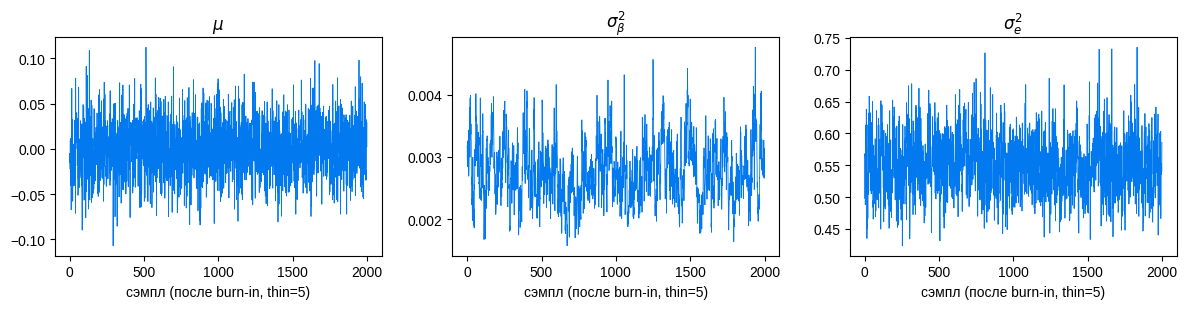

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, k, name in zip(axes, [0, 1, 2], ["$\\mu$", "$\\sigma^2_\\beta$", "$\\sigma^2_e$"]):
    ax.plot(fb["trace"][:, k], lw=0.6, color="#0279EE")
    ax.set_xlabel("сэмпл (после burn-in, thin=5)"); ax.set_title(name)
plt.tight_layout(); plt.show()

## Сверка с RR-BLUP

Модель одна и та же, отличается только способ оценки дисперсий. Значит,
posterior mean β из BRR должно почти совпасть с β̂ из RR-BLUP. Хороший
тест на то, что сэмплер написан правильно.

corr(beta_BRR, beta_RRBLUP) = 0.9981
sigma2_e: BRR posterior = 0.549, REML = 0.541
sigma2_b: BRR posterior = 0.00276, REML = 0.00283


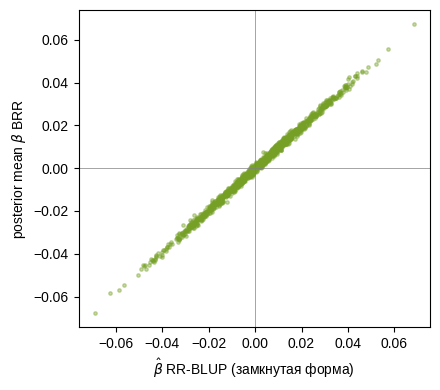

In [4]:
lam, vc = rrblup.lam_from_reml(y, X)
Z, _, c = pp.center_markers(X)
fr = rrblup.rrblup_fit(y, Z, lam)

print(f"corr(beta_BRR, beta_RRBLUP) = {np.corrcoef(fb['beta'], fr['beta'])[0,1]:.4f}")
print(f"sigma2_e: BRR posterior = {fb['sigma2_e']:.3f}, REML = {vc['sigma2_e']:.3f}")
print(f"sigma2_b: BRR posterior = {fb['sigma2_b']:.5f}, REML = {vc['sigma2_g']/c:.5f}")

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.scatter(fr["beta"], fb["beta"], s=6, alpha=0.4, color="#75A025")
ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel("$\\hat\\beta$ RR-BLUP (замкнутая форма)")
ax.set_ylabel("posterior mean $\\beta$ BRR")
plt.tight_layout(); plt.show()

## Что тут важно

- Цикл по маркерам «вернуть вклад → обновить β_j → вычесть вклад» —
  основа всего. В BayesA (04) он же, только со своей дисперсией на маркер.
- posterior mean β совпало с RR-BLUP (corr > 0.99) — сэмплер работает.
- σ²_β теперь не константа, а случайная величина со своим posterior.
- Цена вопроса: ~10 секунд на 12k итераций (спасибо numba) против
  миллисекунд у замкнутой формы.